# Two-stage procedure vs single-stage DF (experiment 1)

`slurm_jobs/DF_wc003_experiments/exp1_validate_two_stage.slurm` (+ `packed_long_runs.slurm` for the
single-stage arm). Per cell (grid pair x VPL/CESS, 4 days, 5 MWh as 10 units), DistFlow (SOCP) at
`objective=current_congestion` with the flat `w_current * sum(ell)` term:

| run | what |
|---|---|
| **full** | DF on the broad candidate set, up to 24 h |
| **two-stage** | LDF siting (1 h) -> DF on the stage-1 sites, 4 h in total |
| **baseline** | DF at `fix_gamma_n={}`: no storage |

**Congestion reduction** of the two-stage procedure = the share of the full procedure's reduction it attains:

$$r = \frac{O_\text{no storage} - O_\text{two-stage}}{O_\text{no storage} - O_\text{full}}$$

- `r_pgm` -- every $O$ is the **pgm** re-pricing of that run's dispatch (the real target), on the
  squared current-excess term alone (`current_congestion_objective`; the `w_current` term is left out).
- `r_model` -- the same, on the DF model's own congestion term (as solved).
- `r_UB` -- in the DF model's TOTAL objective, against the full run's incumbent.
- `r_LB` -- in the DF model's TOTAL objective, against the full run's **best bound**: the reduction no DF
  siting can beat, so `r_LB` is a guaranteed share of the attainable optimum. There is no pgm bound, so it
  only exists in model space, and it is on the total because the solver's bound is.

`r > 1` means the two-stage run beat the (time-limited) full run. A full run that has not finished yet
(no `results.json`) is marked `*` and its `r` is NaN.

`PLOT_OBJECTIVE` ("model" / "pgm" / "both") picks which ratios the figure and the paper table show; under
"both" the model bars are hatched.

In [1]:
print("Cell Started")
from IPython.display import clear_output, display

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path.cwd().parent))   # paper_companion/: vpl_results.py, shared by every experiment
import vpl_results as vr   # the run reader for slurm_jobs/DF_wc003_experiments/

print("Cell Finished")
clear_output()
pd.set_option("display.width", 250)

In [2]:
# USED_GRIDS = ["C0S0", "S0R0", "R0C0"]   # only these grid pairs are loaded, tabled and plotted
USED_GRIDS = ["C0S0"]
GRIDS = vr.grid_pairs(USED_GRIDS)           # as the "grids" column spells them ("C0,S0", ...)

# Where the sweep folders (as the scripts wrote them, job_<id>/ subfolders and all) were copied.
RESULTS = Path(r"C:\Users\VerdaasdonkF\OneDrive - University of Twente\Desktop\results\v5_reweighted_261022")
EXP1 = RESULTS / "DF_exp1_two_stage_validation" / "DF_exp1_two_stage_validation"   # single (packed job) + two-stage + baselines
EXP2 = RESULTS / "DF_exp2_vpl_vs_cess" / "DF_exp2_vpl_vs_cess"
EXP3 = RESULTS / "DF_exp3_slack_value" / "DF_exp3_slack_value"

# which objective the figure and the paper table show: "pgm" (AC re-pricing), "model" (DF, as solved) or "both"
PLOT_OBJECTIVE = "both"
vr.objective_columns(PLOT_OBJECTIVE)   # refuses a typo

('pgm_objective', 'objective')

In [3]:
df = vr.load(EXP1, GRIDS)
print("w_current (DF runs):", sorted(df.loc[df["physics"] == "DistFlow", "w_current"].unique()))
df.groupby(["phase", "finished"]).size()

w_current (DF runs): [np.float64(0.03)]


phase     finished
baseline  True        1
single    True        2
stage1    True        2
stage2    True        2
dtype: int64

In [4]:
df

,run,run_dir,phase,job,task,experiment,physics,objective_name,grids,days,...,pgm_capacitances_zeroed,pgm_current_congestion_objective,pgm_current_objective,pgm_voltage_objective,pgm_shedding_objective,pgm_loss_objective,stage1_run,two_stage_wall_s,model_power_objective,model_real_power_objective
0,exp_0_single_C0-S0_Ctot5000_u10_vcctrue_202610...,C:\Users\VerdaasdonkF\OneDrive - University of...,single,job_634024,0,single_C0-S0_Ctot5000_u10_vcctrue,DistFlow,current_congestion,"C0,S0",4,...,True,3.593771,3.621968,0.0,0.0,0.0,None,NaN,NaN,NaN
1,exp_1_single_C0-S0_Ctot5000_u10_vccfalse_20261...,C:\Users\VerdaasdonkF\OneDrive - University of...,single,job_634024,1,single_C0-S0_Ctot5000_u10_vccfalse,DistFlow,current_congestion,"C0,S0",4,...,True,3.303399,3.524114,0.0,0.0,0.0,None,NaN,NaN,NaN
2,exp_12_baseline_C0-S0_20261021_223651,C:\Users\VerdaasdonkF\OneDrive - University of...,baseline,job_634257,12,baseline_C0-S0,DistFlow,current_congestion,"C0,S0",4,...,True,5.795424,3.915773,0.0,0.0,0.0,None,NaN,NaN,NaN
3,exp_6_LDF_C0-S0_Ctot5000_u10_vcctrue_20261021_...,C:\Users\VerdaasdonkF\OneDrive - University of...,stage1,job_634257,6,LDF_C0-S0_Ctot5000_u10_vcctrue,LinDistFlow,congestion,"C0,S0",4,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,8.050367,26.613683
4,exp_7_LDF_C0-S0_Ctot5000_u10_vccfalse_20261021...,C:\Users\VerdaasdonkF\OneDrive - University of...,stage1,job_634257,7,LDF_C0-S0_Ctot5000_u10_vccfalse,LinDistFlow,congestion,"C0,S0",4,...,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,7.435473,26.289338
5,exp_6_DF_C0-S0_Ctot5000_u10_vcctrue_20261021_2...,C:\Users\VerdaasdonkF\OneDrive - University of...,stage2,job_634257,6,DF_C0-S0_Ctot5000_u10_vcctrue,DistFlow,current_congestion,"C0,S0",4,...,True,3.587635,3.669409,0.0,0.0,0.0,exp_6_LDF_C0-S0_Ctot5000_u10_vcctrue_20261021_...,985.0,NaN,NaN
6,exp_7_DF_C0-S0_Ctot5000_u10_vccfalse_20261021_...,C:\Users\VerdaasdonkF\OneDrive - University of...,stage2,job_634257,7,DF_C0-S0_Ctot5000_u10_vccfalse,DistFlow,current_congestion,"C0,S0",4,...,True,3.294181,3.591264,0.0,0.0,0.0,exp_7_LDF_C0-S0_Ctot5000_u10_vccfalse_20261021...,476.0,NaN,NaN


In [5]:
KEY = ["grids", "vcc"]

full = vr.one_per(df[(df["phase"] == "single") & df["finished"]], KEY)
two = vr.one_per(vr.two_stage(df), KEY)
base = vr.one_per(df[df["phase"] == "baseline"], ["grids"])
running = pd.MultiIndex.from_frame(df.loc[(df["phase"] == "single") & ~df["finished"], KEY])

index = two.index.union(full.index).union(running)
T = pd.DataFrame(index=sorted(index, key=lambda k: (vr.GRID_PAIRS.index(k[0]), not k[1])))
T.index = pd.MultiIndex.from_tuples(T.index, names=KEY)
T["full_running"] = T.index.isin(running) & ~T.index.isin(full.index)

# objective columns are <run>_<source>_<term>: run = base / full / two (two-stage),
# source = pgm (AC re-pricing of the dispatch) or model (DF, as solved),
# term = congestion (current_congestion_objective alone) or total (w_current * sum(ell) included)
OBJ = {"pgm_congestion": "pgm_objective", "pgm_total": "pgm_total",
       "model_congestion": "objective", "model_total": "objective_total"}
grids = T.index.get_level_values("grids")
for name, col in OBJ.items():
    T[f"base_{name}"] = grids.map(base[col])
for run, src in (("full", full), ("two", two)):
    for name, col in OBJ.items():
        T[f"{run}_{name}"] = src[col]
T["full_model_total_bound"] = full["bound"]   # the solver's bound is on the TOTAL
for col in ("status", "mip_gap", "n_sites"):
    T[f"full_{col}"] = full[col]
for col in ("s1_status", "status", "mip_gap", "n_sites"):
    T[f"two_{col}"] = two[col]

T["full_time_h"] = full["wall_time_s"] / 3600
T["two_time_h"] = two["time_s"] / 3600
T["two_end_to_end_h"] = two["two_stage_wall_s"] / 3600
T["time_ratio"] = T["two_time_h"] / T["full_time_h"]


def share(term, full_col):
    """(base - two) / (base - full) on `term`, the full run read off `full_col`."""
    return (T[f"base_{term}"] - T[f"two_{term}"]) / (T[f"base_{term}"] - T[full_col])


T["r_pgm"] = share("pgm_congestion", "full_pgm_congestion")
T["r_model"] = share("model_congestion", "full_model_congestion")
T["r_UB"] = share("model_total", "full_model_total")
T["r_LB"] = share("model_total", "full_model_total_bound")
# for scale: how much congestion each procedure removes, in pgm and in model terms
for run in ("full", "two"):
    for name in ("pgm_congestion", "model_congestion"):
        T[f"{run}_{name}_reduction_pct"] = 100 * (1 - T[f"{run}_{name}"] / T[f"base_{name}"])

with pd.option_context("display.float_format", "{:.3f}".format, "display.max_columns", 60):
    display(T)

full_running  base_pgm_congestion  base_pgm_total  base_model_congestion  base_model_total  full_pgm_congestion  full_pgm_total  full_model_congestion  full_model_total  two_pgm_congestion  two_pgm_total  two_model_congestion  \
grids vcc                                                                                                                                                                                                                                        
C0,S0 True          False                5.795           9.711                  5.696             9.653                3.594           7.216                  3.488             7.149               3.588          7.257                 3.481   
      False         False                5.795           9.711                  5.696             9.653                3.303           6.828                  3.190             6.758               3.294          6.885                 3.179   

             two_model_total  full_model_total_bound full_status  full_mip_gap  full_n_sites two_s1_status two_status  two_mip_gap  two_n_sites  full_time_h  two_time_h  two_end_to_end_h  time_ratio  r_pgm  r_model  r_UB  r_LB  \
grids vcc                                                                                                                                                                                                                            
C0,S0 True             7.190                   7.149     OPTIMAL         0.000             9       OPTIMAL    OPTIMAL        0.000            7       13.003       0.227             0.274       0.017  1.003    1.003 0.984 0.984   
      False            6.815                   6.758     OPTIMAL         0.000             7       OPTIMAL    OPTIMAL        0.000            5        0.947       0.113             0.132       0.119  1.004    1.004 0.980 0.980   

             full_pgm_congestion_reduction_pct  full_model_congestion_reduction_pct  two_pgm_congestion_reduction_pct  two_model_congestion_reduction_pct  
grids vcc                                                                                                                                                  
C0,S0 True                              37.990                               38.761                            38.095                              38.888  
      False                             43.000                               43.990                            43.159                              44.185

## The table (paper version)

In [6]:
SHOW_PGM = PLOT_OBJECTIVE in ("pgm", "both")
SHOW_MODEL = PLOT_OBJECTIVE in ("model", "both")

columns = {
    "full: status": T["full_status"].where(~T["full_running"], "RUNNING"),
    "full: gap [%]": 100 * T["full_mip_gap"],
    "full: time [h]": T["full_time_h"],
    "two-stage: time [h]": T["two_time_h"],
    "time ratio [%]": 100 * T["time_ratio"],
}
if SHOW_PGM:
    columns.update({
        "pgm reduction, full [%]": T["full_pgm_congestion_reduction_pct"],
        "pgm reduction, two-stage [%]": T["two_pgm_congestion_reduction_pct"],
        "r_pgm [%]": 100 * T["r_pgm"],
    })
if SHOW_MODEL:
    columns.update({
        "DF reduction, full [%]": T["full_model_congestion_reduction_pct"],
        "DF reduction, two-stage [%]": T["two_model_congestion_reduction_pct"],
        "r_model [%]": 100 * T["r_model"],
        "r_UB [%]": 100 * T["r_UB"],
        "r_LB [%]": 100 * T["r_LB"],
    })
paper = pd.DataFrame(columns)
paper.index = [f"{g} {'VPL' if v else 'CESS'}" for g, v in paper.index]
with pd.option_context("display.float_format", "{:.1f}".format):
    display(paper)
try:
    print(paper.to_latex(float_format="%.1f"))
except ImportError as exc:   # DataFrame.to_latex needs jinja2
    print(f"(no LaTeX export: {exc})")

,full: status,full: gap [%],full: time [h],two-stage: time [h],time ratio [%],"pgm reduction, full [%]","pgm reduction, two-stage [%]",r_pgm [%],"DF reduction, full [%]","DF reduction, two-stage [%]",r_model [%],r_UB [%],r_LB [%]
"C0,S0 VPL",OPTIMAL,0.0,13.0,0.2,1.7,38.0,38.1,100.3,38.8,38.9,100.3,98.4,98.4
"C0,S0 CESS",OPTIMAL,0.0,0.9,0.1,11.9,43.0,43.2,100.4,44.0,44.2,100.4,98.0,98.0


(no LaTeX export: Missing optional dependency 'Jinja2'. DataFrame.style requires jinja2. Use pip or conda to install Jinja2.)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


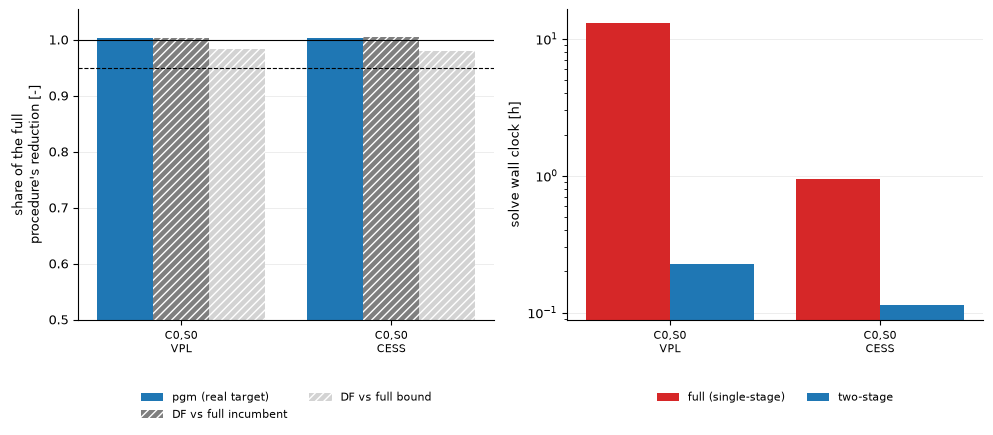

In [7]:
STYLE = {
    "figsize": (10.0, 4.5),
    "save_dir": Path("figs"),       # None -> don't save
    "save_formats": ("eps", "png"),
    "font_size": 9,
    "bars": {   # column -> label, colour, which objective it is read off
        "r_pgm": ("pgm (real target)", "tab:blue", "pgm"),
        "r_model": ("DF vs full incumbent", "tab:grey", "model"),
        "r_LB": ("DF vs full bound", "lightgrey", "model"),
    },
    "model_hatch": "////",           # model bars under PLOT_OBJECTIVE = "both"
    "times": {"full_time_h": ("full (single-stage)", "tab:red"), "two_time_h": ("two-stage", "tab:blue")},
    "target": 0.95,                  # dashed reference line on the parity panel
    "grid_kwargs": {"linestyle": "-", "linewidth": 0.4, "alpha": 0.4},
    # below the axes, so the legend never covers a bar
    "legend_kwargs": {"fontsize": 8, "frameon": False, "loc": "upper center", "bbox_to_anchor": (0.5, -0.2), "ncol": 2},
}
plt.rcParams.update({"font.size": STYLE["font_size"], "savefig.dpi": 300})


def save_fig(fig, name, style=STYLE):
    if style["save_dir"] is None:
        return
    style["save_dir"].mkdir(parents=True, exist_ok=True)
    for fmt in style["save_formats"]:
        fig.savefig(style["save_dir"] / f"{name}.{fmt}", bbox_inches="tight")


bars = {c: b for c, b in STYLE["bars"].items() if PLOT_OBJECTIVE in (b[2], "both")}
labels = [f"{g}\n{'VPL' if v else 'CESS'}{'*' if T.loc[(g, v), 'full_running'] else ''}" for g, v in T.index]
x = np.arange(len(T))
fig, (ax_r, ax_t) = plt.subplots(1, 2, figsize=STYLE["figsize"])

w = 0.8 / len(bars)
for k, (col, (label, color, source)) in enumerate(bars.items()):
    hatch = STYLE["model_hatch"] if PLOT_OBJECTIVE == "both" and source == "model" else None
    ax_r.bar(x + (k - (len(bars) - 1) / 2) * w, T[col], w, label=label, color=color, hatch=hatch,
             edgecolor="white" if hatch else None, linewidth=0)
ax_r.axhline(1.0, color="black", linewidth=0.8)
ax_r.axhline(STYLE["target"], color="black", linewidth=0.8, linestyle="--")
ax_r.set_ylabel("share of the full\nprocedure's reduction [-]")
values = T[list(bars)].values.astype(float)
if np.isfinite(values).any():
    ax_r.set_ylim(min(0.5, np.nanmin(values) - 0.05), max(1.05, np.nanmax(values) + 0.05))

w = 0.8 / len(STYLE["times"])
for k, (col, (label, color)) in enumerate(STYLE["times"].items()):
    ax_t.bar(x + (k - (len(STYLE["times"]) - 1) / 2) * w, T[col], w, label=label, color=color)
ax_t.set_yscale("log")
ax_t.set_ylabel("solve wall clock [h]")

for ax in (ax_r, ax_t):
    ax.set_xticks(x, labels, fontsize=8)
    ax.grid(True, axis="y", **STYLE["grid_kwargs"])
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(**STYLE["legend_kwargs"])
fig.tight_layout()
if T["full_running"].any():
    print("* full (single-stage) run still running: no r, no full time")
save_fig(fig, f"00_two_stage_parity_and_time_{PLOT_OBJECTIVE}")

In [8]:
# where do the two procedures put the units? (sites only in one of them)
for key, row in T.iterrows():
    g_full = full.loc[key, "gamma_n"] if key in full.index else {}
    g_two = two.loc[key, "gamma_n"] if key in two.index else {}
    print(key, "\n  full     :", dict(sorted(g_full.items())), "\n  two-stage:", dict(sorted(g_two.items())),
          "\n  only full:", sorted(set(g_full) - set(g_two)), " only two-stage:", sorted(set(g_two) - set(g_full)))

('C0,S0', True) 
  full     : {1: 1, 23: 1, 66: 1, 89: 1, 97: 1, 110: 1, 121: 2, 132: 1, 206: 1} 
  two-stage: {3: 2, 23: 1, 89: 1, 107: 1, 121: 2, 132: 2, 206: 1} 
  only full: [1, 66, 97, 110]  only two-stage: [3, 107]
('C0,S0', False) 
  full     : {23: 1, 66: 1, 89: 2, 110: 1, 121: 1, 132: 3, 206: 1} 
  two-stage: {23: 1, 89: 3, 121: 1, 132: 4, 208: 1} 
  only full: [66, 110, 206]  only two-stage: [208]
